# 08 · Evaluation metrics

Maths unit **M10**. Read `eval/metrics.py`, `eval/replay.py` and `eval/study.py`.

How do we know a rung is better? This notebook checks the metric examples by hand, shows why replay must be time-ordered, and walks through the statistics every study in EVALUATION.md uses: a paired bootstrap interval and a sign test, with the verdict rule.

**Everything below that involves a user is SIMULATED** (`eval/sim.py`). Real labels only exist once Alen swipes.

In [1]:
import glob, json, time
import numpy as np
import matplotlib.pyplot as plt

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings

state = AppState(get_settings())
state.load()
features = state.require_features()
print(f"{len(features):,} pool images loaded")

Archive ladder reached rule 5: no external drive and only 42.7 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


50,000 pool images loaded


## 1 · M10 by hand

In [2]:
from visualtaste.eval.metrics import ndcg_at_k, roc_auc
from sklearn.metrics import roc_auc_score

y, s = np.array([1, 1, 0, 0]), np.array([0.9, 0.6, 0.7, 0.2])
print("AUC:", roc_auc(y, s), " scikit-learn agrees:", roc_auc_score(y, s))
print("NDCG@5 of gains [1, 0, 2, 0, 1]:", round(ndcg_at_k([1, 0, 2, 0, 1], 5), 3))

AUC: 0.75  scikit-learn agrees: 0.75
NDCG@5 of gains [1, 0, 2, 0, 1]: 0.699


## 2 · Why replay is time-ordered

On a cached simulated history, fit R3 two ways: on a random 80% (testing on the rest), and on the first 80% in time (testing on the last 20%). The random split lets the model train on the future.

In [3]:
from scipy.special import expit
from visualtaste.eval.study import SeedResult
from visualtaste.rec.features import design_matrix
from visualtaste.rec.labels import ACTION_TO_TARGET
from visualtaste.rec.r3_logreg import fit_sklearn

path = sorted(glob.glob("../data/eval/phase9_rungs/S1_semantic/r3/seed_*.json"))[0]
r = SeedResult.from_json(open(path, encoding="utf-8").read())
X = design_matrix(features, ("sig",))[features.positions(r.image_ids)].astype(float)
y = np.array([ACTION_TO_TARGET[a] for a in r.actions], float)
cut = int(0.8 * len(y))
for name, train in (("random 80%", np.random.default_rng(0).permutation(len(y))[:cut]), ("first 80% in time", np.arange(cut))):
    test = np.setdiff1d(np.arange(len(y)), train)
    w, b = fit_sklearn(X[train], y[train], np.ones(len(train)), lam=1.0)
    print(f"{name:>18}: test AUC {roc_auc(y[test].astype(int), expit(X[test] @ w + b)):.3f}")

        random 80%: test AUC 0.575
 first 80% in time: test AUC 0.563


The two numbers above are the measured result for this one history. Whichever way they fall here, the time-ordered one is the honest estimate, because serving always predicts the future from the past.

## 3 · The statistics behind every verdict

From the cached phase9_rungs study, the like rates of R3 and R2 on S1, paired by seed.

20 paired seeds: mean difference +0.073, 90% CI [+0.049, +0.097]
sign test: 19 wins, 1 losses, p = 4.01e-05
verdict: supported


Text(0.5, 1.0, 'Per-seed differences (the bootstrap resamples these)')

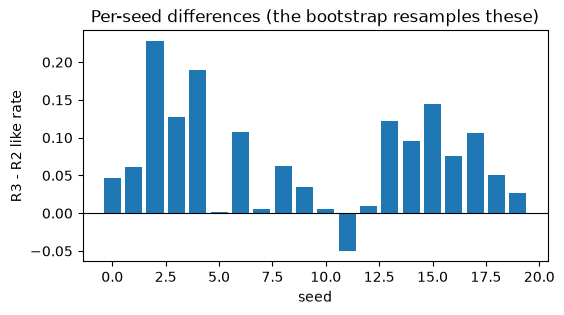

In [4]:
from visualtaste.eval.metrics import paired_bootstrap, sign_test

def rates(spec):
    out = {}
    for p in glob.glob(f"../data/eval/phase9_rungs/S1_semantic/{spec}/seed_*.json"):
        res = SeedResult.from_json(open(p, encoding="utf-8").read())
        out[res.seed] = res.like_rate
    return out

a, b = rates("r3"), rates("r2")
seeds = sorted(set(a) & set(b))
first, second = np.array([a[s] for s in seeds]), np.array([b[s] for s in seeds])
diff, low, high = paired_bootstrap(first, second, samples=10_000)
wins, losses = int((first > second).sum()), int((first < second).sum())
print(f"{len(seeds)} paired seeds: mean difference {diff:+.3f}, 90% CI [{low:+.3f}, {high:+.3f}]")
print(f"sign test: {wins} wins, {losses} losses, p = {sign_test(wins, losses):.3g}")
print("verdict:", "inconclusive" if low <= 0 <= high else ("supported" if low > 0 else "not supported"))
plt.figure(figsize=(6, 3)); plt.bar(range(len(seeds)), first - second); plt.axhline(0, color="k", lw=0.8)
plt.xlabel("seed"); plt.ylabel("R3 - R2 like rate"); plt.title("Per-seed differences (the bootstrap resamples these)")